In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import os
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import statsmodels.api as sm
from scipy.spatial import cKDTree
from scipy.optimize import minimize
from sklearn.cluster import KMeans

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 140)

#Settings
These are the dials for the whole study, "near a camera" means within 250m. Each camera is followed for 24 months before and 36 months after go-live. Control places must be at least 600m from any camera so cameras cannot affect them and each camera gets 5 twins

In [4]:
RADIUS_M = 250
PRE_MONTHS = 24
POST_MONTHS = 36
START = "2015-01-01"
MIN_CRAHES = 100
GRID_M = 500
N_CONTROLS = 5
BUFFER_M = 600


In [5]:
from google.colab import drive
drive.mount("/content/drive")

source_data = "/content/drive/MyDrive/chicago_car_crash/Traffic_Crashes_-_Crashes_20261009.csv"
keep = ["CRASH_RECORD_ID", "CRASH_DATE", "LATITUDE", "LONGITUDE", "INJURIES_TOTAL", "POSTED_SPEED_LIMIT"]

import os, pandas as pd
os.makedirs("data", exist_ok=True)

parts = []
for chunk in pd.read_csv(source_data, usecols=keep, chunksize=200_000):
    chunk.columns = [c.lower() for c in chunk.columns]
    chunk["crash_date"] = pd.to_datetime(chunk["crash_date"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")
    chunk = chunk.dropna(subset=["crash_date", "latitude", "longitude"])
    parts.append(chunk[chunk["crash_date"] >= "2015-01-01"])

pd.concat(parts, ignore_index=True).to_csv("data/crashes.csv", index=False)
print(pd.read_csv("data/crashes.csv").shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(1093506, 6)


In [6]:
BASE = "https://data.cityofchicago.org/resource"
HEADERS = {}

'''
Three assignments on one line (tuple unpacking):

dict(params or {}) copies the params dict. params or {} turns None into an empty dict. Copying avoids changing the caller’s dict.
rows = [] collects records from all pages.
offset = 0 is how many rows to skip. The first page starts at 0.
'''
def fetch_all(dataset_id, params=None, page=50000, max_rows=5000000):
    params, rows, offset = dict(params or {}), [], 0
    while offset < max_rows:
        p = {**params, "$limit": page, "$offset": offset, "$order": ":id"}
        '''$limit: maximum rows to return.
           $offset: how many rows to skip.
           $order=":id": sorts by Socrata’s hidden, stable row ID. '''

        r = requests.get(f"{BASE}/{dataset_id}.json", params=p, headers=HEADERS, timeout=180)
        r.raise_for_status()
        chunk = r.json()
        if not chunk:
            break
        rows += chunk
        offset += page
        print(f"  {dataset_id}: {len(rows):,} rows", end="\r")
    print()
    return pd.DataFrame(rows)

def cached(path, fn):
    if os.path.exists(path):
        return pd.read_csv(path)
    df = fn(); df.to_csv(path, index=False); return df

cams_raw = cached("data/cameras.csv", lambda: fetch_all("4i42-qv3h"))

crashes_raw = pd.read_csv("data/crashes.csv")

def fetch_and_group_violations():
    df = fetch_all("hhkd-xvj4", {
        "$select": "camera_id, violation_date, violations"
    })
    df["violations"] = pd.to_numeric(df["violations"], errors="coerce")
    df["month"] = pd.to_datetime(df["violation_date"]).dt.to_period("M").astype(str)
    grouped = df.groupby(["camera_id", "month"], as_index=False)["violations"].sum()
    return grouped

viol_raw = cached("data/violations_monthly.csv", fetch_and_group_violations)

print(cams_raw.shape, crashes_raw.shape, viol_raw.shape)
cams_raw.head(3)

  4i42-qv3h: 209 rows

(209, 9) (1093506, 6) (21827, 3)


,id,location_id,address,first_approach,go_live_date,latitude,longitude,location,second_approach
0,219,CHI096,4429 N Broadway Ave,NB,2013-11-23T00:00:00.000,41.9626,-87.6555,"{'latitude': '41.9626', 'longitude': '-87.6555...",NaN
1,23,CHI186,2638 W Fullerton Ave,WB,2023-03-10T00:00:00.000,41.9249,-87.6941,"{'latitude': '41.9249', 'longitude': '-87.6941...",EB
2,21,CHI193,7508 W Touhy Ave,WB,2023-03-02T00:00:00.000,42.0116,-87.8142,"{'latitude': '42.0116', 'longitude': '-87.8142...",EB


In [7]:
need = {
    "cameras":    (cams_raw,    ["go_live_date", "latitude", "longitude"]),
    "crashes":    (crashes_raw, ["crash_date", "latitude", "longitude"]),
    "violations": (viol_raw,    ["camera_id", "month", "violations"]),
}
for name, (df, cols) in need.items():
    missing = [c for c in cols if c not in df.columns]
    print(f"{name:10s} columns: {list(df.columns)}")
    assert not missing, f"{name} is missing {missing} - rename them in the cleaning cells below"

cameras    columns: ['id', 'location_id', 'address', 'first_approach', 'go_live_date', 'latitude', 'longitude', 'location', 'second_approach']
crashes    columns: ['crash_record_id', 'crash_date', 'posted_speed_limit', 'injuries_total', 'latitude', 'longitude']
violations columns: ['camera_id', 'month', 'violations']


In [10]:
# cameras
cams = cams_raw.copy()
cams["go_live"] = pd.to_datetime(cams["go_live_date"], errors="coerce")
cams["lat"] = pd.to_numeric(cams["latitude"], errors="coerce")
cams["lon"] = pd.to_numeric(cams["longitude"], errors="coerce")
cams = (cams.dropna(subset=["go_live", "lat", "lon"])
            .drop_duplicates(subset=["lat", "lon"])
            .reset_index(drop=True))
cams["go_month"] = cams["go_live"].dt.to_period("M").dt.to_timestamp()
print("Cameras with usable data:", len(cams))
print(cams["go_live"].dt.year.value_counts().sort_index().to_string())

# crashes
cr = crashes_raw.copy()
cr["date"] = pd.to_datetime(cr["crash_date"], errors="coerce")
cr["lat"] = pd.to_numeric(cr["latitude"], errors="coerce")
cr["lon"] = pd.to_numeric(cr["longitude"], errors="coerce")
cr = cr.dropna(subset=["date", "lat", "lon"])
cr = cr[cr.lat.between(41.6, 42.05) & cr.lon.between(-87.95, -87.5)]
cr["month"] = cr["date"].dt.to_period("M").dt.to_timestamp()

END = cr["month"].max() - pd.DateOffset(months=2)
months = pd.date_range(START, END, freq="MS")
cr = cr[cr["month"].isin(months)].reset_index(drop=True)
T = len(months)
print(f"Crashes kept: {len(cr):,}   |   months: {months[0].date()} -> {months[-1].date()}  (T={T})")

Cameras with usable data: 209
go_live
2013    39
2014    78
2015     6
2018    12
2021     1
2023    20
2024     3
2025    48
2026     2
Crashes kept: 1,081,469   |   months: 2015-01-01 -> 2026-08-01  (T=140)


In [12]:
LAT0, LON0 = 41.85, -87.65 #A reference point near the center of Chicago. All positions are measured in metres from it.
def to_xy(lat, lon):
    x = (np.asarray(lon) - LON0) * 111_320 * np.cos(np.radians(LAT0))
    y = (np.asarray(lat) - LAT0) * 110_574
    return np.column_stack([x, y])

crash_xy = to_xy(cr["lat"], cr["lon"])
crash_tree = cKDTree(crash_xy)
crash_month_idx = months.get_indexer(cr["month"])

def monthly_counts(sites_xy, radius=RADIUS_M):
    neighbours = crash_tree.query_ball_point(sites_xy, r=radius)
    out = np.zeros((len(sites_xy), T), dtype=np.int32)
    for i, idx in enumerate(neighbours):
        if idx:
            out[i] = np.bincount(crash_month_idx[idx], minlength=T)
    return out

cam_xy = to_xy(cams["lat"], cams["lon"])
Y_cam = monthly_counts(cam_xy)
print("Y_cam shape (cameras x months):", Y_cam.shape)
print("Average crashes per camera-month:", Y_cam.mean().round(2))

Y_cam shape (cameras x months): (209, 140)
Average crashes per camera-month: 4.74


In [13]:
cam_tree = cKDTree(cam_xy)
xmin, ymin = crash_xy.min(0); xmax, ymax = crash_xy.max(0)
gx, gy = np.meshgrid(np.arange(xmin, xmax, GRID_M), np.arange(ymin, ymax, GRID_M))
grid = np.column_stack([gx.ravel(), gy.ravel()])

grid = grid[cam_tree.query(grid)[0] > BUFFER_M]
Y_grid = monthly_counts(grid)
busy = Y_grid.sum(1) >= MIN_CRAHES
ctl_xy, Y_ctl = grid[busy], Y_grid[busy]
print(f"Candidate control sites: {len(Y_ctl):,}")

Candidate control sites: 1,224


In [14]:
cams["go_idx"] = months.get_indexer(cams["go_month"])
eligible = cams.index[(cams.go_idx >= PRE_MONTHS) & (cams.go_idx + POST_MONTHS <= T)].to_numpy()
print(f"Cameras eligible for the study: {len(eligible)} of {len(cams)}")

def mean_slope(Y, lo, hi):
    seg = Y[:, lo:hi].astype(float)
    t = np.arange(hi - lo) - (hi - lo - 1) / 2
    return seg.mean(1), (seg * t).sum(1) / (t ** 2).sum()

rel = np.arange(-PRE_MONTHS, POST_MONTHS)
pieces, matches = [], {}
for c in eligible:
    g = int(cams.at[c, "go_idx"])
    m_t, s_t = mean_slope(Y_cam[[c]], g - PRE_MONTHS, g)
    m_c, s_c = mean_slope(Y_ctl, g - PRE_MONTHS, g)
    dist = np.abs(m_c - m_t) / m_c.std() + np.abs(s_c - s_t) / (s_c.std() + 1e-9)
    best = np.argsort(dist)[:N_CONTROLS]
    matches[c] = best
    cols = np.arange(g - PRE_MONTHS, g + POST_MONTHS)
    pieces.append(pd.DataFrame({"stack": c, "unit": f"T{c}", "treated": 1, "rel": rel, "y": Y_cam[c, cols]}))
    for j in best:
        pieces.append(pd.DataFrame({"stack": c, "unit": f"C{j}_s{c}", "treated": 0, "rel": rel, "y": Y_ctl[j, cols]}))

panel = pd.concat(pieces, ignore_index=True)
panel["post"] = (panel["rel"] >= 0).astype(int)
panel["tp"] = panel["treated"] * panel["post"]
print("Panel rows:", len(panel))

bal = panel[panel.post == 0].groupby("treated")["y"].mean()
print("\nAvg monthly crashes BEFORE go-live  ->  twins: %.2f | cameras: %.2f" % (bal[0], bal[1]))

Cameras eligible for the study: 33 of 209
Panel rows: 11880

Avg monthly crashes BEFORE go-live  ->  twins: 4.30 | cameras: 4.40


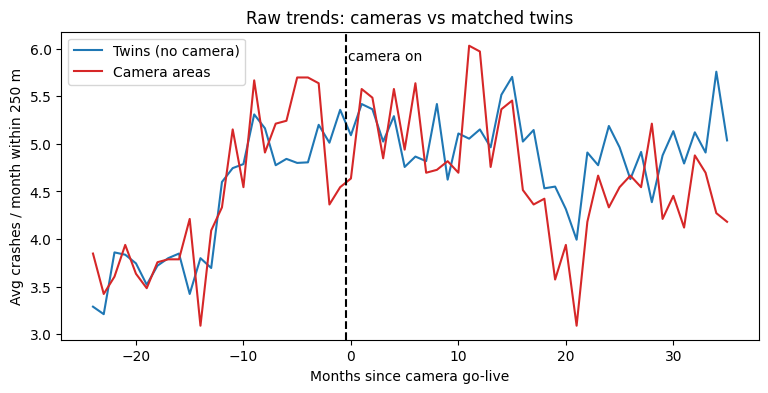

In [ ]:
avg = panel.groupby(["treated", "rel"])["y"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(avg.index, avg[0], label="Twins (no camera)", color="tab:blue")
ax.plot(avg.index, avg[1], label="Camera areas", color="tab:red")
ax.axvline(-0.5, color="k", ls="--"); ax.text(-0.3, ax.get_ylim()[1]*0.97, "camera on", va="top")
ax.set_xlabel("Months since camera go-live"); ax.set_ylabel("Avg crashes / month within 250 m")
ax.set_title("Raw trends: cameras vs matched twins"); ax.legend(); plt.show()

In [15]:
def pct(res, name):
    b = res.params[name]; lo, hi = res.conf_int().loc[name]
    return (np.exp(b) - 1) * 100, (np.exp(lo) - 1) * 100, (np.exp(hi) - 1) * 100, res.pvalues[name]

cl = {"groups": panel["stack"].values}
ols  = smf.ols("y ~ treated + post + tp", data=panel).fit(cov_type="cluster", cov_kwds=cl)
pois = smf.glm("y ~ treated + post + tp", data=panel, family=sm.families.Poisson()).fit(cov_type="cluster", cov_kwds=cl)

print("OLS: change in crashes per month near a camera (vs twins): %.3f  (95%% CI %.3f to %.3f), p=%.4f" %
      (ols.params["tp"], *ols.conf_int().loc["tp"], ols.pvalues["tp"]))
e, lo, hi, p = pct(pois, "tp")
print("Poisson: %% change in crashes near a camera (vs twins): %.1f%%  (95%% CI %.1f%% to %.1f%%), p=%.4f" % (e, lo, hi, p))

OLS: change in crashes per month near a camera (vs twins): -0.356  (95% CI -0.711 to -0.000), p=0.0497
Poisson: % change in crashes near a camera (vs twins): -7.3%  (95% CI -13.6% to -0.6%), p=0.0342


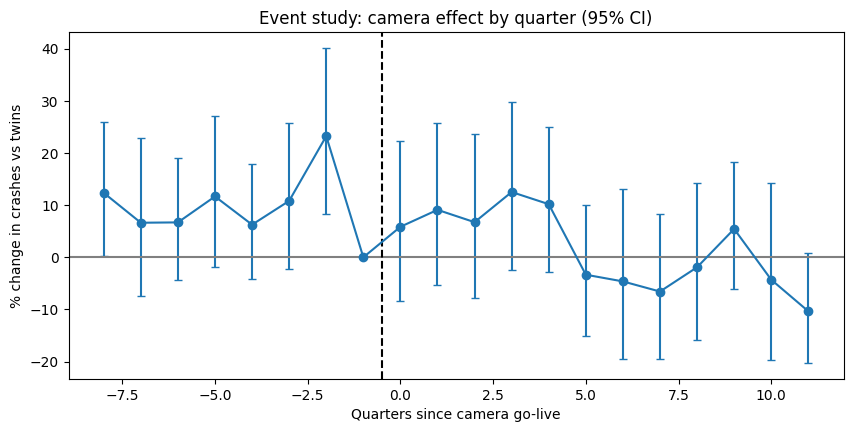

In [16]:
panel["q"] = np.floor(panel["rel"] / 3).astype(int)
qs = sorted(k for k in panel["q"].unique() if k != -1)
names = {}
for k in qs:
    nm = "tq_" + str(k).replace("-", "m")
    panel[nm] = ((panel["treated"] == 1) & (panel["q"] == k)).astype(int)
    names[k] = nm

formula = "y ~ treated + C(q) + " + " + ".join(names.values())
es = smf.glm(formula, data=panel, family=sm.families.Poisson()).fit(cov_type="cluster", cov_kwds={"groups": panel["stack"].values})

est = pd.DataFrame({
    "q": qs,
    "pct":  [(np.exp(es.params[names[k]]) - 1) * 100 for k in qs],
    "lo":   [(np.exp(es.conf_int().loc[names[k]][0]) - 1) * 100 for k in qs],
    "hi":   [(np.exp(es.conf_int().loc[names[k]][1]) - 1) * 100 for k in qs],
})
est = pd.concat([est, pd.DataFrame({"q": [-1], "pct": [0.0], "lo": [0.0], "hi": [0.0]})]).sort_values("q")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.errorbar(est.q, est.pct, yerr=[est.pct - est.lo, est.hi - est.pct], fmt="o-", capsize=3)
ax.axhline(0, color="gray"); ax.axvline(-0.5, color="k", ls="--")
ax.set_xlabel("Quarters since camera go-live"); ax.set_ylabel("% change in crashes vs twins")
ax.set_title("Event study: camera effect by quarter (95% CI)"); plt.show()

In [17]:
panel["yrs"]    = panel["rel"] / 12
panel["post_t"] = panel["post"] * panel["yrs"]
panel["tp_t"]   = panel["tp"] * panel["yrs"]

dec = smf.glm("y ~ treated + post + post_t + tp + tp_t", data=panel, family=sm.families.Poisson()
              ).fit(cov_type="cluster", cov_kwds={"groups": panel["stack"].values})

print(f"Effect at go-live (tp):          {(np.exp(dec.params['tp'])-1)*100:6.1f}%   p={dec.pvalues['tp']:.4f}")
print(f"Change in effect per year (tp_t): {dec.params['tp_t']:+.3f} log-points   p={dec.pvalues['tp_t']:.4f}")
print("  (positive & significant => effect is fading)\n")
for m in [6, 12, 24, 35]:
    t = dec.t_test(f"tp + {m/12} * tp_t = 0")
    b, (lo, hi) = float(t.effect[0]), t.conf_int()[0]
    print(f"  effect {m:>2d} months after go-live: {(np.exp(b)-1)*100:6.1f}%   (95% CI {(np.exp(lo)-1)*100:6.1f}% to {(np.exp(hi)-1)*100:6.1f}%)")

Effect at go-live (tp):             1.1%   p=0.8287
Change in effect per year (tp_t): -0.061 log-points   p=0.0271
  (positive & significant => effect is fading)

  effect  6 months after go-live:   -2.0%   (95% CI   -9.5% to    6.2%)
  effect 12 months after go-live:   -4.9%   (95% CI  -11.4% to    2.1%)
  effect 24 months after go-live:  -10.5%   (95% CI  -17.5% to   -2.9%)
  effect 35 months after go-live:  -15.3%   (95% CI  -24.5% to   -5.1%)


 region  cameras  effect_pct      lo      hi     p
SW (#2)        7     -16.708 -21.941 -11.123 0.000
NW (#1)        8     -10.249 -26.247   9.219 0.280
NW (#3)       10      -2.919 -12.420   7.612 0.573
SE (#0)        8       0.295 -15.187  18.602 0.973


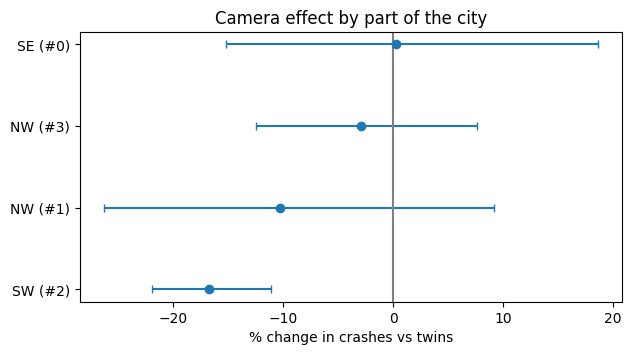

In [18]:
ec = cams.loc[eligible].copy()
ec[["x", "y"]] = to_xy(ec["lat"], ec["lon"])
km = KMeans(n_clusters=4, n_init=10, random_state=0).fit(ec[["x", "y"]])
ec["cluster"] = km.labels_

def label(k):
    cx, cy = km.cluster_centers_[k]
    return ("N" if cy > 0 else "S") + ("E" if cx > 0 else "W")
ec["region"] = [f"{label(k)} (#{k})" for k in ec["cluster"]]
panel["region"] = panel["stack"].map(ec["region"])

rows = []
for r, sub in panel.groupby("region"):
    m = smf.glm("y ~ treated + post + tp", data=sub, family=sm.families.Poisson()).fit(
        cov_type="cluster", cov_kwds={"groups": sub["stack"].values})
    e, lo, hi, p = pct(m, "tp")
    rows.append(dict(region=r, cameras=sub["stack"].nunique(), effect_pct=e, lo=lo, hi=hi, p=p))
het = pd.DataFrame(rows).sort_values("effect_pct")
print(het.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.errorbar(het.effect_pct, range(len(het)), xerr=[het.effect_pct - het.lo, het.hi - het.effect_pct], fmt="o", capsize=3)
ax.set_yticks(range(len(het))); ax.set_yticklabels(het.region); ax.axvline(0, color="gray")
ax.set_xlabel("% change in crashes vs twins"); ax.set_title("Camera effect by part of the city"); plt.show()

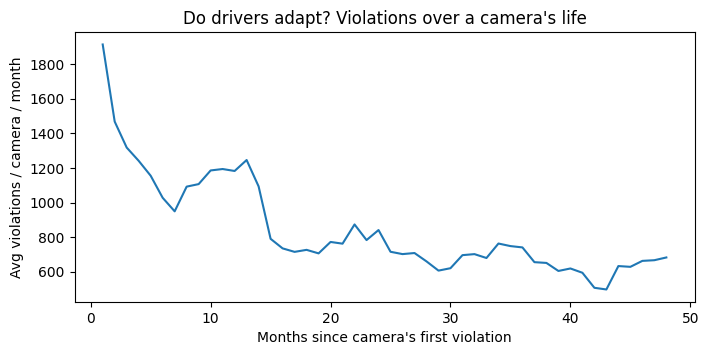

In [19]:
v = viol_raw.copy()
v["month"] = pd.to_datetime(v["month"], errors="coerce")
v["violations"] = pd.to_numeric(v["violations"], errors="coerce")
v = v.dropna(subset=["month", "violations", "camera_id"])
first = v.groupby("camera_id")["month"].transform("min")
v["months_since"] = ((v["month"].dt.year - first.dt.year) * 12 + (v["month"].dt.month - first.dt.month))
curve = v[v.months_since.between(1, 48)].groupby("months_since")["violations"].mean()

fig, ax = plt.subplots(figsize=(8, 3.5))
curve.plot(ax=ax)
ax.set_xlabel("Months since camera's first violation"); ax.set_ylabel("Avg violations / camera / month")
ax.set_title("Do drivers adapt? Violations over a camera's life"); plt.show()

In [20]:
def fit_synth(y_pre, X_pre):
    J = X_pre.shape[1]
    f = lambda w: np.sum((y_pre - X_pre @ w) ** 2)
    jac = lambda w: -2 * X_pre.T @ (y_pre - X_pre @ w)
    res = minimize(f, np.ones(J) / J, jac=jac, method="SLSQP",
                   bounds=[(0, 1)] * J,
                   constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1, "jac": lambda w: np.ones(J)}],
                   options={"maxiter": 500})
    return res.x

def run_synth(y, X, g, post_len=POST_MONTHS, top=100):
    mu_y, mu_X = y[:g].mean(), X[:g].mean(0)
    yd, Xd = y - mu_y, X - mu_X
    pre_err = ((Xd[:g] - yd[:g, None]) ** 2).sum(0)
    keep = np.argsort(pre_err)[:top]
    w = fit_synth(yd[:g], Xd[:g][:, keep])
    synth = Xd[:, keep] @ w + mu_y
    gap = y - synth
    rmspe_pre  = np.sqrt(np.mean(gap[:g] ** 2))
    rmspe_post = np.sqrt(np.mean(gap[g:g + post_len] ** 2))
    return dict(w=w, keep=keep, synth=synth, gap=gap, pre=rmspe_pre, post=rmspe_post, ratio=rmspe_post / (rmspe_pre + 1e-9))

Cohort go-live: 2023-03-01  |  cameras in cohort: 9
Pre-treatment RMSPE : 0.803   (small = good fit)
Post-treatment RMSPE: 0.815
Avg post-period gap : 0.268 crashes/month per camera  =  6.3% vs synthetic


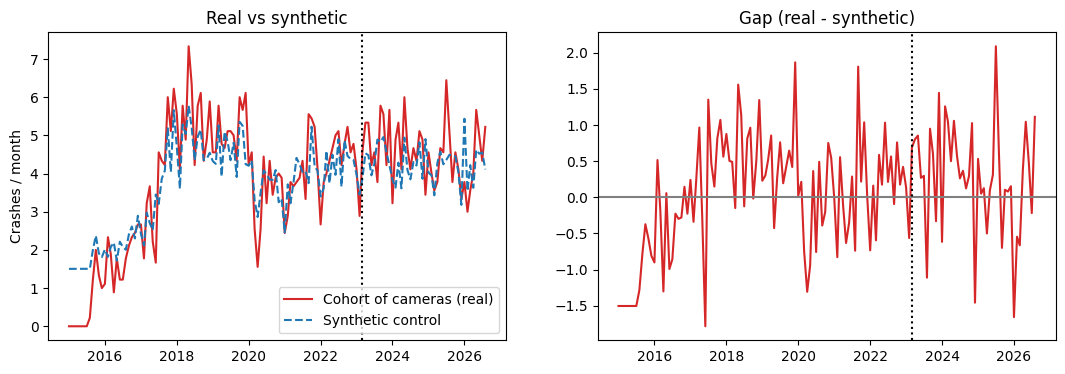

In [21]:
cohort_month = cams.loc[eligible].groupby("go_idx").size().idxmax()
cohort = cams.index[(cams.go_idx == cohort_month)].intersection(eligible)
g = int(cohort_month)
print(f"Cohort go-live: {months[g].date()}  |  cameras in cohort: {len(cohort)}")

y_tr = Y_cam[cohort].mean(0).astype(float)
X_don = Y_ctl.T.astype(float)
sc = run_synth(y_tr, X_don, g)

print(f"Pre-treatment RMSPE : {sc['pre']:.3f}   (small = good fit)")
print(f"Post-treatment RMSPE: {sc['post']:.3f}")
post_slice = slice(g, g + POST_MONTHS)
eff = (y_tr[post_slice] - sc['synth'][post_slice]).mean()
base = sc['synth'][post_slice].mean()
print(f"Avg post-period gap : {eff:.3f} crashes/month per camera  =  {100*eff/base:.1f}% vs synthetic")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.plot(months, y_tr, label="Cohort of cameras (real)", color="tab:red")
ax.plot(months, sc["synth"], label="Synthetic control", color="tab:blue", ls="--")
ax.axvline(months[g], color="k", ls=":"); ax.legend(); ax.set_title("Real vs synthetic"); ax.set_ylabel("Crashes / month")
ax = axes[1]
ax.plot(months, sc["gap"], color="tab:red"); ax.axhline(0, color="gray"); ax.axvline(months[g], color="k", ls=":")
ax.set_title("Gap (real - synthetic)"); plt.show()

Pseudo p-value (RMSPE ratio, two-sided): 0.960
Pseudo p-value (avg gap as negative as ours, one-sided): 0.590


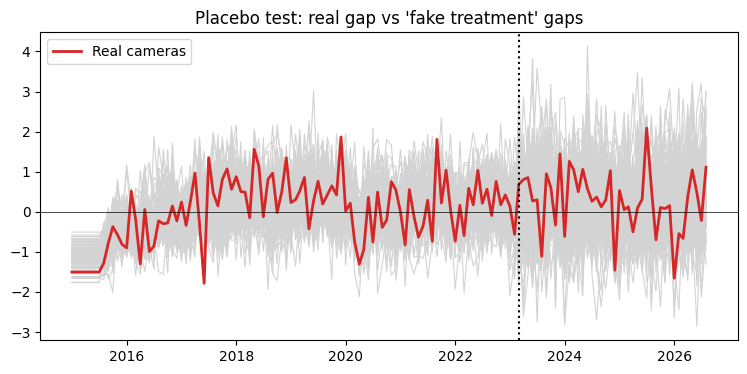

In [22]:
rng = np.random.default_rng(0)
n_coh, J = len(cohort), Y_ctl.shape[0]
n_placebo = 100
placebo = []
for _ in range(n_placebo):
    pick = rng.choice(J, size=n_coh, replace=False)
    rest = np.setdiff1d(np.arange(J), pick)
    y_p = Y_ctl[pick].mean(0).astype(float)
    placebo.append(run_synth(y_p, Y_ctl[rest].T.astype(float), g))

ratios = np.array([p["ratio"] for p in placebo])
post_gap_p = np.array([p["gap"][post_slice].mean() for p in placebo])
p_ratio = (ratios >= sc["ratio"]).mean()
p_neg   = (post_gap_p <= eff).mean()
print(f"Pseudo p-value (RMSPE ratio, two-sided): {p_ratio:.3f}")
print(f"Pseudo p-value (avg gap as negative as ours, one-sided): {p_neg:.3f}")

fig, ax = plt.subplots(figsize=(9, 4))
for p in placebo:
    if p["pre"] < 2 * sc["pre"] + 1e-9:
        ax.plot(months, p["gap"], color="lightgray", lw=0.8)
ax.plot(months, sc["gap"], color="tab:red", lw=2, label="Real cameras")
ax.axhline(0, color="k", lw=0.5); ax.axvline(months[g], color="k", ls=":")
ax.set_title("Placebo test: real gap vs 'fake treatment' gaps"); ax.legend(); plt.show()

Posterior mean effect: -7.1%   94% interval: -15.8% to 2.6%
P(cameras reduce crashes) = 0.922


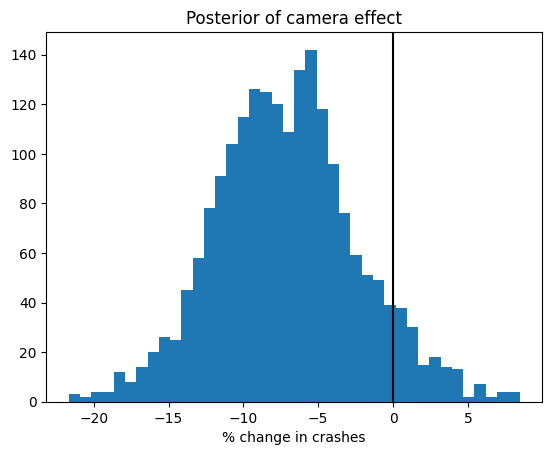

In [23]:
try:
    import pymc as pm
    agg = panel.groupby(["treated", "rel"]).agg(y=("y", "sum"), n=("unit", "nunique")).reset_index()
    agg["post"] = (agg["rel"] >= 0).astype(int)
    tr, po, n = agg.treated.values, agg.post.values, agg.n.values

    with pm.Model() as model:
        a   = pm.Normal("a", 0, 2)
        b   = pm.Normal("b", 0, 1)
        c   = pm.Normal("c", 0, 1)
        tau = pm.Normal("tau", 0, 0.5)
        alpha = pm.Exponential("alpha", 0.05)
        mu = pm.math.exp(a + b * tr + c * po + tau * tr * po) * n
        pm.NegativeBinomial("obs", mu=mu, alpha=alpha, observed=agg.y.values)
        idata = pm.sample(1000, tune=1000, chains=2, target_accept=0.9, random_seed=1, progressbar=False)

    draws = (np.exp(idata.posterior["tau"].values.ravel()) - 1) * 100
    print(f"Posterior mean effect: {draws.mean():.1f}%   94% interval: {np.percentile(draws,3):.1f}% to {np.percentile(draws,97):.1f}%")
    print(f"P(cameras reduce crashes) = {(draws < 0).mean():.3f}")
    plt.hist(draws, bins=40); plt.axvline(0, color="k"); plt.xlabel("% change in crashes"); plt.title("Posterior of camera effect"); plt.show()
except ImportError:
    print("PyMC not installed - run: pip install pymc   (optional step)")

In [24]:
e, lo, hi, p = pct(pois, "tp")
summary = pd.DataFrame([
    ["DiD (Poisson, matched twins)", f"{e:.1f}%", f"[{lo:.1f}%, {hi:.1f}%]", f"p={p:.3f}"],
    ["Synthetic control (largest cohort)", f"{100*eff/base:.1f}%", "see placebo plot", f"pseudo-p={p_neg:.3f}"],
    ["Decay: change in effect per year", f"{dec.params['tp_t']:+.3f} log-pts", "", f"p={dec.pvalues['tp_t']:.3f}"],
], columns=["Method", "Estimated effect", "95% interval", "Significance"])
summary

,Method,Estimated effect,95% interval,Significance
0,"DiD (Poisson, matched twins)",-7.3%,"[-13.6%, -0.6%]",p=0.034
1,Synthetic control (largest cohort),6.3%,see placebo plot,pseudo-p=0.590
2,Decay: change in effect per year,-0.061 log-pts,,p=0.027
